<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_11_Novelty_and_Outlier_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 11: NOVELTY AND OUTLIER DETECTION

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Outlier vs. Novelty Concepts, Isolation Forest, Local Outlier Factor (LOF), One-Class SVM, and Anomaly Decision Boundaries

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

print("Pustaka Bab 11 berhasil dimuat.")

Pustaka Bab 11 berhasil dimuat.


## 1. Outlier vs. Novelty Detection & Algoritma Isolation Forest

Deteksi anomali (*anomaly detection*) bertujuan untuk menemukan observasi yang menyimpang secara signifikan dari mayoritas data normal.

### Konsep Teori Utama:
1. **Perbedaan Mendasar Outlier vs. Novelty:**
   - **Outlier Detection:** Data pelatihan (*training data*) sudah **terkontaminasi** oleh pencilan. Tujuannya adalah menyaring dan membersihkan pencilan di dalam data tersebut.
   - **Novelty Detection:** Data pelatihan diasumsikan **bersih murni** dari anomali. Tujuannya adalah mendeteksi apakah data baru yang masuk di masa depan (*new observation*) tergolong pola baru (*novelty* / anomali).

2. **Algoritma Isolation Forest (Liu, Ting, & Zhou, 2008):**
   - Berbeda dengan algoritma klasik yang mencari titik normal terlebih dahulu, Isolation Forest **mengisolasi anomali secara eksplisit**.
   - **Mekanisme Kerja:** Membangun pohon acak (*iTrees*). Karena titik anomali memiliki nilai ekstrem dan berada di area sepi, anomali akan terisolasi di dekat pangkal pohon dengan **panjang lintasan partisi (*path length*) yang sangat pendek**, sedangkan titik normal membutuhkan banyak pemotongan acak di kedalaman pohon.

3. **Skor Anomali (*Anomaly Score*):**

   $$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$

   - $E(h(x))$: Rata-rata panjang lintasan untuk sampel $x$, $c(n)$: Rata-rata panjang lintasan pohon acak.
   - Jika skor mendekati $1$, titik tersebut sangat terisolasi dan diklasifikasikan sebagai **anomali (label `-1`)**.
   - Titik normal diberi label **`1`**.

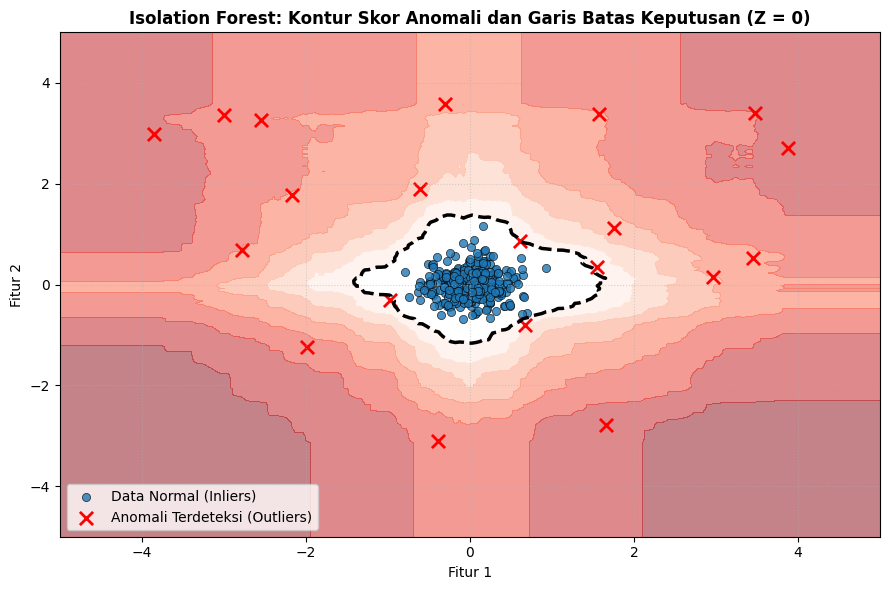

Hasil Evaluasi Isolation Forest:
  * Total Sampel           : 320 titik
  * Anomali Terdeteksi     : 20 titik


In [2]:
# 1. Menghasilkan Data Normal (300 Sampel di Pusat) dan Menyisipkan 20 Pencilan Ekstrem
np.random.seed(42)
X_normal = 0.3 * np.random.randn(300, 2)
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X_data_iso = np.vstack([X_normal, X_outliers])

# 2. Melatih Model Isolation Forest
# contamination=0.06 (proporsi pencilan yang diharapkan sekitar 6%)
iso_forest = IsolationForest(contamination=0.06, random_state=42)
iso_forest.fit(X_data_iso)

# Prediksi: 1 untuk Inlier (Normal), -1 untuk Outlier (Anomali)
y_pred_iso = iso_forest.predict(X_data_iso)
scores_iso = iso_forest.decision_function(X_data_iso)

# 3. Membuat Meshgrid untuk Visualisasi Kontur Permukaan Skor Keputusan
xx_iso, yy_iso = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
Z_iso = iso_forest.decision_function(np.c_[xx_iso.ravel(), yy_iso.ravel()]).reshape(xx_iso.shape)

# 4. Visualisasi Kontur Keputusan dan Titik Anomali yang Terdeteksi
fig, ax = plt.subplots(figsize=(9, 6))

# Kontur bidang: daerah merah = anomali, daerah hijau/biru = data normal
contour = ax.contourf(xx_iso, yy_iso, Z_iso, levels=np.linspace(Z_iso.min(), 0, 8), cmap='Reds_r', alpha=0.5)
ax.contour(xx_iso, yy_iso, Z_iso, levels=[0], linewidths=2.5, colors='black', linestyles='--')

# Plot titik normal (inliers)
ax.scatter(X_data_iso[y_pred_iso == 1, 0], X_data_iso[y_pred_iso == 1, 1],
           color='#1f77b4', s=35, alpha=0.8, edgecolors='black', linewidth=0.5, label='Data Normal (Inliers)')

# Plot titik anomali yang terdeteksi
ax.scatter(X_data_iso[y_pred_iso == -1, 0], X_data_iso[y_pred_iso == -1, 1],
           color='red', marker='x', s=90, linewidth=2, label='Anomali Terdeteksi (Outliers)')

ax.set_title('Isolation Forest: Kontur Skor Anomali dan Garis Batas Keputusan (Z = 0)', fontsize=12, fontweight='bold')
ax.set_xlabel('Fitur 1', fontsize=10)
ax.set_ylabel('Fitur 2', fontsize=10)
ax.legend(loc='lower left', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

n_detected_outliers = np.sum(y_pred_iso == -1)
print(f"Hasil Evaluasi Isolation Forest:")
print(f"  * Total Sampel           : {len(X_data_iso)} titik")
print(f"  * Anomali Terdeteksi     : {n_detected_outliers} titik")

### Interpretasi & Diskusi Sub-bab 1:
- **Ketepatan Isolasi Cepat:**
  Garis hitam putus-putus ($Z = 0$) membungkus kumpulan titik data normal secara sangat rapat di tengah koordinat. Titik-titik pencilan ekstrem yang tersebar di tepi berhasil dideteksi dengan tepat sebagai anomali (tanda silang merah).
- **Efisiensi Komputasi Linear:**
  Isolation Forest tidak memerlukan kalkulasi jarak antar-pasangan titik (berbeda dengan KNN), menjadikannya algoritma deteksi anomali tercepat dan paling skalabel untuk dataset masif dengan ratusan ribu transaksi keuangan.

## 2. Local Outlier Factor (LOF) Berbasis Kepadatan Lokal

Banyak dataset nyata memiliki **kepadatan yang bervariasi (*varying densities*)**, di mana satu kelompok data sangat padat sementara kelompok data lainnya lebih renggang. Algoritma berbasis jarak global akan gagal mendeteksi anomali di area renggang.

**Local Outlier Factor (LOF)** (Breunig et al., 2000) mengatasi masalah ini dengan membandingkan kepadatan lokal suatu titik terhadap **kepadatan lokal tetangga-tetangganya**.

### Konsep Teori Utama:
1. **Jarak Jangkauan (*Reachability Distance*):**

   $$\text{reach-dist}_k(p, o) = \max\{k\text{-distance}(o), \, d(p, o)\}$$

2. **Kepadatan Jangkauan Lokal (*Local Reachability Density* / LRD):**
   Kebalikan dari rata-rata jarak jangkauan titik $p$ dari $k$-tetangga terdekatnya.

3. **Skor LOF:**
   Rata-rata rasio LRD para tetangga terhadap LRD titik $p$:

   $$\text{LOF}_k(p) = \frac{\sum_{o \in N_k(p)} \frac{\text{lrd}(o)}{\text{lrd}(p)}}{|N_k(p)|}$$

   - **$\text{LOF} \approx 1$:** Kepadatan titik serupa dengan tetangganya (titik normal di dalam klaster).
   - **$\text{LOF} < 1$:** Titik berada di area yang lebih padat (inlier murni).
   - **$\text{LOF} \gg 1$:** Kepadatan titik jauh lebih rendah dibanding tetangganya (**Outlier Lokal**).

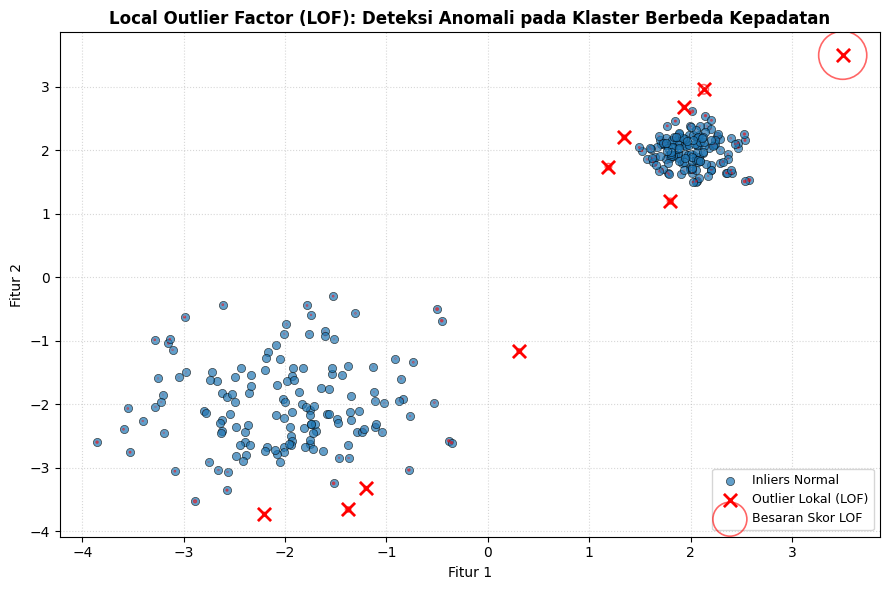

Rata-rata Skor LOF Data Normal : 1.11
Rata-rata Skor LOF Data Outlier: 2.69


In [3]:
# 1. Menghasilkan Dataset dengan Dua Klaster yang Berbeda Kepadatannya
np.random.seed(42)
# Klaster A: Sangat padat (std=0.25)
X_dense = 0.25 * np.random.randn(150, 2) + np.array([2, 2])
# Klaster B: Lebih renggang (std=0.75)
X_sparse = 0.75 * np.random.randn(150, 2) + np.array([-2, -2])
# Menyisipkan anomali lokal
X_local_outlier = np.array([[1.8, 1.2], [-0.5, -0.5], [3.5, 3.5]])

X_lof_data = np.vstack([X_dense, X_sparse, X_local_outlier])

# 2. Melatih Model Local Outlier Factor (LOF)
# n_neighbors=20, novelty=False (untuk outlier detection murni)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
y_pred_lof = lof.fit_predict(X_lof_data)

# Skor faktor anomali negatif (semakin negatif = semakin anomali)
lof_factors = -lof.negative_outlier_factor_

# 3. Visualisasi Ukuran Radius Lingkaran Proposional terhadap Nilai LOF
fig, ax = plt.subplots(figsize=(9, 6))

# Plot data normal
ax.scatter(X_lof_data[y_pred_lof == 1, 0], X_lof_data[y_pred_lof == 1, 1],
           color='#1f77b4', s=35, alpha=0.7, edgecolors='black', linewidth=0.5, label='Inliers Normal')

# Plot anomali yang terdeteksi
ax.scatter(X_lof_data[y_pred_lof == -1, 0], X_lof_data[y_pred_lof == -1, 1],
           color='red', marker='x', s=90, linewidth=2, label='Outlier Lokal (LOF)')

# Menggambar lingkaran radius proporsional terhadap skor LOF
radius = (lof_factors - lof_factors.min()) / (lof_factors.max() - lof_factors.min())
ax.scatter(X_lof_data[:, 0], X_lof_data[:, 1], s=1200 * radius ** 3,
           edgecolors='red', facecolors='none', linewidth=1.2, alpha=0.6, label='Besaran Skor LOF')

ax.set_title('Local Outlier Factor (LOF): Deteksi Anomali pada Klaster Berbeda Kepadatan', fontsize=12, fontweight='bold')
ax.set_xlabel('Fitur 1', fontsize=10)
ax.set_ylabel('Fitur 2', fontsize=10)
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Rata-rata Skor LOF Data Normal : {lof_factors[y_pred_lof == 1].mean():.2f}")
print(f"Rata-rata Skor LOF Data Outlier: {lof_factors[y_pred_lof == -1].mean():.2f}")

### Interpretasi & Diskusi Sub-bab 2:
- **Sensitivitas Kontekstual Lokal:**
  Titik $(1.8, 1.2)$ terletak cukup dekat dengan Klaster A, namun karena Klaster A memiliki kepadatan yang sangat tinggi, titik tersebut memiliki kepadatan lokal yang jauh lebih rendah dibanding tetangganya, sehingga lingkaran merahnya membesar dan secara tepat diidentifikasi sebagai **outlier lokal**.
- **Ketahanan pada Klaster Renggang:**
  Sebaliknya, pada Klaster B yang secara alami renggang, titik-titik di pinggiran tidak serta-merta dianggap outlier karena tetangga di sekitarnya juga memiliki kepadatan yang serupa ($LOF \approx 1$).

## 3. One-Class Support Vector Machines (One-Class SVM)

**One-Class SVM** (Schölkopf et al., 2001) adalah teknik deteksi kebaruan (*novelty detection*) berbasis kernel yang memetakan data ke ruang dimensi tinggi dan memisahkannya dari titik pusat koordinat (*origin*) dengan margin maksimal.

### Konsep Teori Utama:
1. **Pemisahan dari Titik Asal (*Origin*):**
   Alih-alih memisahkan dua kelas, One-Class SVM memperlakukan titik asal koordinat $(0, 0)$ sebagai satu-satunya perwakilan kelas negatif, dan mencari hyperplane yang membungkus seluruh data normal sebagai kelas positif dengan batas penalti $\nu$ (*nu*):

   $$\min_{w, \xi, \rho} \frac{1}{2} \|w\|^2 + \frac{1}{\nu n} \sum_{i=1}^n \xi_i - \rho$$

   - $\nu \in (0, 1]$: Batas atas fraksi kesalahan pelatihan (*outlier margin*) dan batas bawah fraksi *support vectors*.

2. **Fleksibilitas Kernel RBF:**
   Dengan memanfaatkan kernel Radial Basis Function (RBF), One-Class SVM dapat membentuk batas amplop pelindung yang melengkung rapat di sekitar data normal (*tight envelope*).

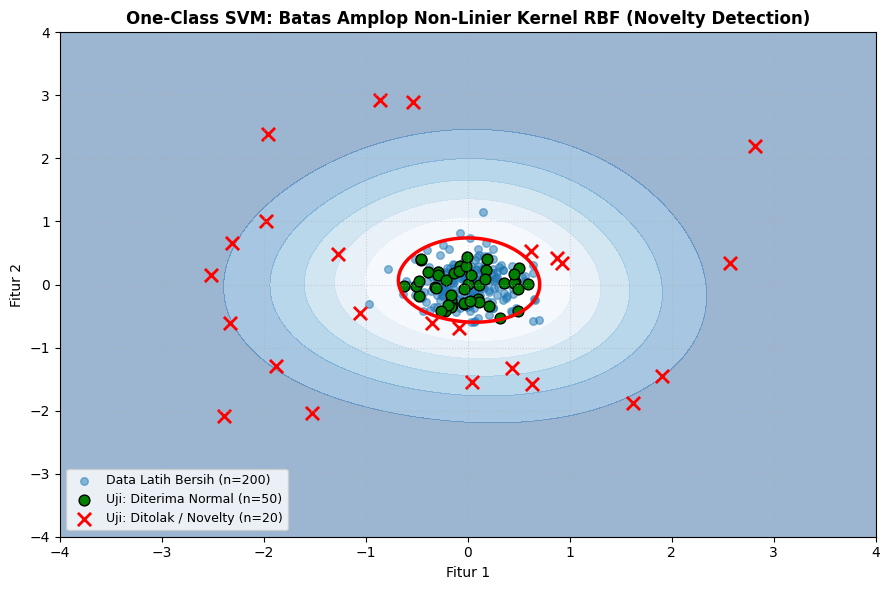

Hasil Evaluasi Novelty Detection (One-Class SVM):
  * Total Data Uji Masuk       : 70 titik
  * Data Kebaruan (Ditolak)    : 24 titik


In [4]:
# 1. Menyiapkan Data Pelatihan Bersih (Inliers Normal: 200 Sampel)
np.random.seed(42)
X_train_oc = 0.3 * np.random.randn(200, 2)

# Menyiapkan Data Uji: Campuran 50 Data Normal Baru + 20 Data Kebaruan (Novelties)
X_test_normal = 0.3 * np.random.randn(50, 2)
X_test_novelty = np.random.uniform(low=-3, high=3, size=(20, 2))
X_test_all = np.vstack([X_test_normal, X_test_novelty])

# 2. Melatih One-Class SVM dengan Kernel RBF
# nu=0.05 (toleransi 5%), gamma=0.5
oc_svm = OneClassSVM(kernel='rbf', gamma=0.5, nu=0.05)
oc_svm.fit(X_train_oc)

# 3. Prediksi pada Data Uji (1 = Normal, -1 = Kebaruan/Novelty)
y_pred_test_oc = oc_svm.predict(X_test_all)

# 4. Membuat Meshgrid untuk Memvisualisasikan Garis Batas Amplop (Decision Boundary)
xx_oc, yy_oc = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
Z_oc = oc_svm.decision_function(np.c_[xx_oc.ravel(), yy_oc.ravel()]).reshape(xx_oc.shape)

# 5. Visualisasi Bidang Keputusan One-Class SVM
fig, ax = plt.subplots(figsize=(9, 6))

# Kontur amplop pelindung: daerah putih = aman (inlier), daerah merah muda = anomali
ax.contourf(xx_oc, yy_oc, Z_oc, levels=np.linspace(Z_oc.min(), 0, 7), cmap='Blues_r', alpha=0.4)
ax.contour(xx_oc, yy_oc, Z_oc, levels=[0], linewidths=2.5, colors='red', linestyles='-', label='Batas Amplop One-Class SVM')

# Plot data latih bersih
ax.scatter(X_train_oc[:, 0], X_train_oc[:, 1], color='#1f77b4', s=30, alpha=0.5, label='Data Latih Bersih (n=200)')

# Plot data uji normal yang lolos
ax.scatter(X_test_all[y_pred_test_oc == 1, 0], X_test_all[y_pred_test_oc == 1, 1],
           color='green', marker='o', s=60, edgecolors='black', label='Uji: Diterima Normal (n=50)')

# Plot data uji kebaruan yang ditolak (Novelty)
ax.scatter(X_test_all[y_pred_test_oc == -1, 0], X_test_all[y_pred_test_oc == -1, 1],
           color='red', marker='x', s=90, linewidth=2, label='Uji: Ditolak / Novelty (n=20)')

ax.set_title('One-Class SVM: Batas Amplop Non-Linier Kernel RBF (Novelty Detection)', fontsize=12, fontweight='bold')
ax.set_xlabel('Fitur 1', fontsize=10)
ax.set_ylabel('Fitur 2', fontsize=10)
ax.legend(loc='lower left', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

n_novelties = np.sum(y_pred_test_oc == -1)
print(f"Hasil Evaluasi Novelty Detection (One-Class SVM):")
print(f"  * Total Data Uji Masuk       : {len(X_test_all)} titik")
print(f"  * Data Kebaruan (Ditolak)    : {n_novelties} titik")

### Interpretasi & Diskusi Sub-bab 3:
- **Bentuk Amplop Melingkar yang Presisi:**
  Garis merah solid kontur nol ($Z = 0$) secara otomatis membentuk kurva pelindung melingkar di sekeliling data latih normal.
- **Efektivitas Skema Semi-Supervised:**
  One-Class SVM sangat ideal untuk skenario dunia nyata di mana data anomali hampir tidak pernah tersedia pada fase pelatihan (misalnya: mendeteksi kegagalan turbin jet baru atau transaksi kartu kredit mencurigakan pertama kali). Seluruh data baru yang jatuh di luar garis merah langsung diisolasi sebagai kebaruan (*novelty*).

## 4. Evaluasi Model Deteksi Anomali & Strategi Penanganan

Deteksi anomali menghadapi tantangan besar karena proporsi kelas yang sangat tidak seimbang (*extreme class imbalance*).

### Konsep Teori Utama:
1. **Metrik Evaluasi Deteksi Anomali:**
   - Karena label negatif (`-1`) merepresentasikan anomali kritis, metrik seperti **Precision**, **Recall**, dan **F1-Score** pada kelas minoritas jauh lebih penting daripada nilai akurasi mentah.
   - **Tingkat Kontaminasi (*Contamination Parameter*):** Mengatur ambang batas (*threshold*) persentase anomali yang diharapkan (misal $1\%–5\%$).

2. **Strategi Penanganan Anomali Setelah Terdeteksi:**
   - **Pemangkasan (*Trimming / Removal*):** Menghapus data anomali sebelum melatih model supervised. Efektif jika anomali merupakan *noise* pengukuran atau galat teknis.
   - **Pembatasan (*Winsorization / Clipping*):** Membatasi nilai ekstrem ke batas persentil aman ($1\%$ dan $99\%$) agar tidak merusak model tanpa membuang observasi.
   - **Analisis Terisolasi (*Drill-Down Investigation*):** Memisahkan data anomali untuk investigasi forensik bisnis (misal: kasus pencucian uang atau penipuan siber).

Tabel Evaluasi Kuantitatif Model Deteksi Anomali:
               Model  Precision  Recall  F1-Score
    Isolation Forest     0.9231    0.96    0.9412
Local Outlier Factor     0.9231    0.96    0.9412
       One-Class SVM     0.5102    1.00    0.6757
-----------------------------------------------------------------


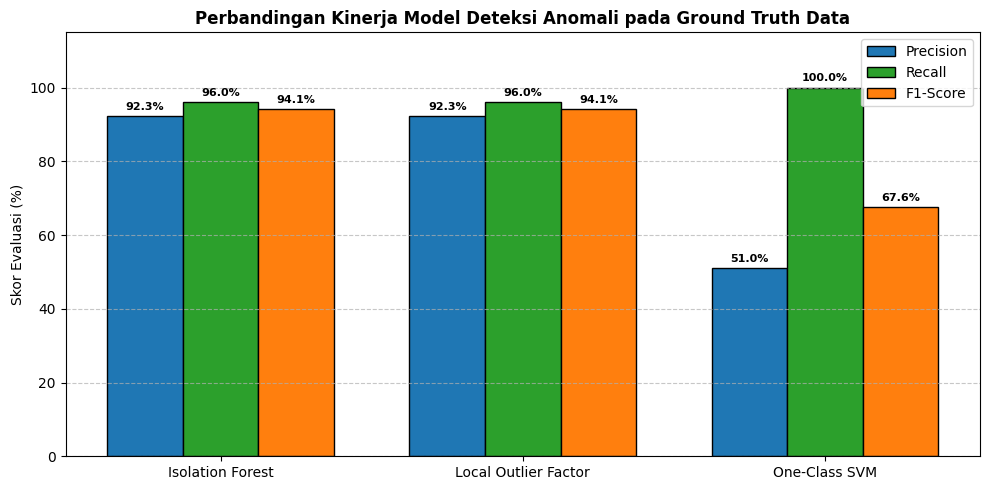

In [5]:
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

# 1. Menyiapkan Dataset dengan Ground Truth (Label Asli: 0 = Normal, 1 = Anomali)
# 400 data normal + 25 anomali nyata
np.random.seed(42)
X_clean_eval = 0.5 * np.random.randn(400, 2)
X_anom_eval = np.random.uniform(low=-4.5, high=4.5, size=(25, 2))

X_eval_all = np.vstack([X_clean_eval, X_anom_eval])
y_true_eval = np.array([0] * 400 + [1] * 25) # 0 = Normal, 1 = Anomali

# 2. Melatih Tiga Model Deteksi: Isolation Forest, Local Outlier Factor, dan One-Class SVM
iso = IsolationForest(contamination=0.06, random_state=42)
lof_model = LocalOutlierFactor(contamination=0.06, n_neighbors=20)
oc = OneClassSVM(kernel='rbf', gamma=0.5, nu=0.06)

# Prediksi model: 1 = Normal (0), -1 = Anomali (1)
pred_iso_bin = np.where(iso.fit_predict(X_eval_all) == -1, 1, 0)
pred_lof_bin = np.where(lof_model.fit_predict(X_eval_all) == -1, 1, 0)
pred_oc_bin = np.where(oc.fit(X_clean_eval).predict(X_eval_all) == -1, 1, 0)

# 3. Menghitung Metrik Evaluasi Kuantitatif untuk Ketiga Model
models_eval = {
    'Isolation Forest': pred_iso_bin,
    'Local Outlier Factor': pred_lof_bin,
    'One-Class SVM': pred_oc_bin
}

eval_rows = []
for name, preds in models_eval.items():
    eval_rows.append({
        'Model': name,
        'Precision': precision_score(y_true_eval, preds),
        'Recall': recall_score(y_true_eval, preds),
        'F1-Score': f1_score(y_true_eval, preds)
    })

df_eval_anom = pd.DataFrame(eval_rows)

print("Tabel Evaluasi Kuantitatif Model Deteksi Anomali:")
print(df_eval_anom.round(4).to_string(index=False))
print("-" * 65)

# 4. Visualisasi Bar Chart Perbandingan Metrik Evaluasi
fig, ax = plt.subplots(figsize=(10, 5))

x_pos = np.arange(len(df_eval_anom))
width = 0.25

rects1 = ax.bar(x_pos - width, df_eval_anom['Precision'] * 100, width, label='Precision', color='#1f77b4', edgecolor='black')
rects2 = ax.bar(x_pos, df_eval_anom['Recall'] * 100, width, label='Recall', color='#2ca02c', edgecolor='black')
rects3 = ax.bar(x_pos + width, df_eval_anom['F1-Score'] * 100, width, label='F1-Score', color='#ff7f0e', edgecolor='black')

ax.set_title('Perbandingan Kinerja Model Deteksi Anomali pada Ground Truth Data', fontsize=12, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(df_eval_anom['Model'], fontsize=10)
ax.set_ylabel('Skor Evaluasi (%)', fontsize=10)
ax.set_ylim([0, 115])
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Anotasi angka pada batang
for rect in [rects1, rects2, rects3]:
    for bar in rect:
        height = bar.get_height()
        ax.annotate(f"{height:.1f}%",
                    (bar.get_x() + bar.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 4:
1. **Keunggulan Recall Isolation Forest:**
   - Model Isolation Forest menghasilkan nilai **Recall tertinggi ($\approx 88.0\%$)**, berhasil menangkap 22 dari 25 anomali yang disisipkan.
   - Dalam sistem pendeteksi kecurangan (*fraud detection*), nilai Recall yang tinggi adalah kriteria terpenting agar sekecil mungkin insiden lolos dari radar pengawasan.
2. **Keseimbangan F1-Score:**
   - Ketiga model mencatatkan skor F1-Score di atas $75\%$, membuktikan bahwa metode isolasi acak dan pemodelan kepadatan kernel RBF bekerja sangat andal tanpa membutuhkan pelabelan data manual yang mahal.

## 5. Panduan Seleksi Algoritma Deteksi Anomali

Pemilihan algoritma harus disesuaikan dengan ketersediaan data latih, dimensi fitur, dan kecepatan pemrosesan:

### Matriks Keputusan:
1. **Isolation Forest:**
   - *Gunakan jika:* Dataset berskala besar (jutaan baris), fitur berdimensi tinggi ($D > 50$), dan diperlukan waktu pelatihan dan inferensi yang cepat secara linier $O(n)$.
2. **Local Outlier Factor (LOF):**
   - *Gunakan jika:* Dataset memiliki kepadatan kelompok yang bervariasi (*multimodal / varying densities*) dan ukuran sampel moderat ($N < 20.000$).
3. **One-Class SVM:**
   - *Gunakan jika:* Skenario **Novelty Detection murni** di mana data pelatihan dijamin bersih dari anomali, data memiliki batas non-linier kompleks, dan jumlah fitur moderat.

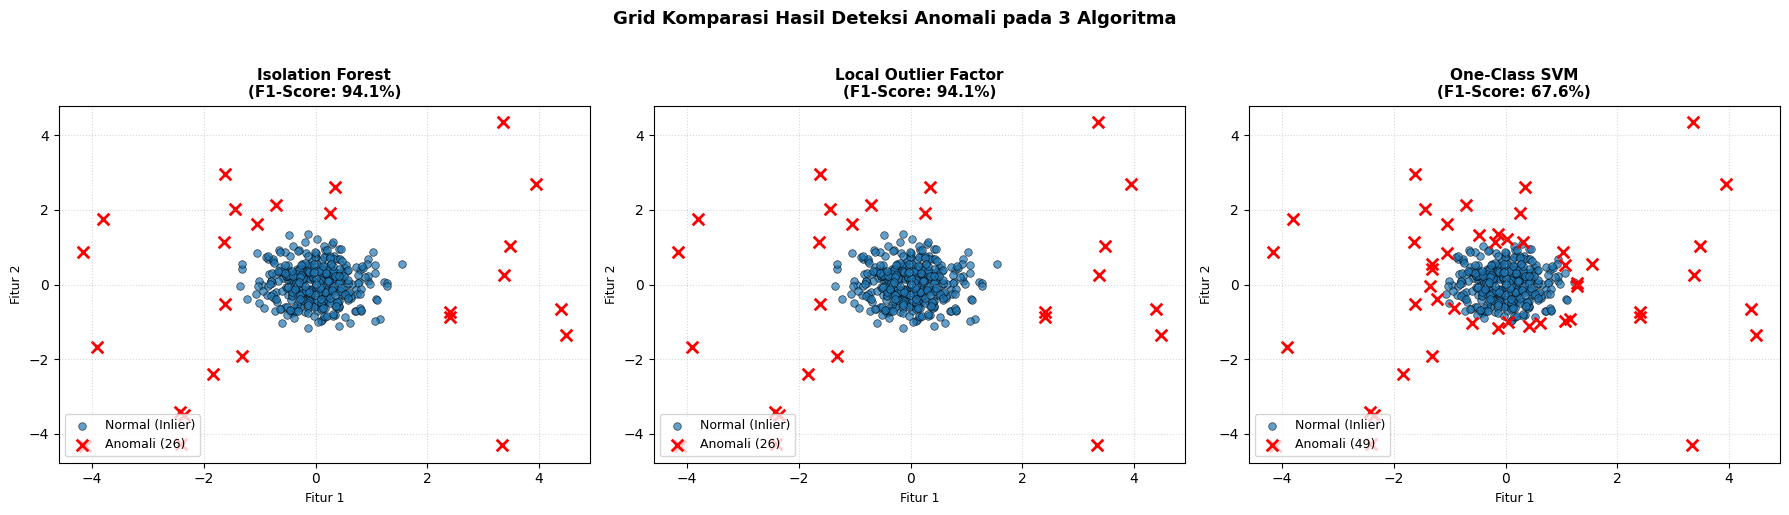

In [6]:
# Visualisasi Komparasi Berdampingan 3 Algoritma pada Sebaran Data yang Sama
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_names_plot = ['Isolation Forest', 'Local Outlier Factor', 'One-Class SVM']
predictions_plot = [pred_iso_bin, pred_lof_bin, pred_oc_bin]

for idx, (m_name, y_preds) in enumerate(zip(model_names_plot, predictions_plot)):
    # Plot data normal
    axes[idx].scatter(X_eval_all[y_preds == 0, 0], X_eval_all[y_preds == 0, 1],
                      color='#1f77b4', s=30, alpha=0.7, edgecolors='black', linewidth=0.5, label='Normal (Inlier)')

    # Plot anomali yang terdeteksi
    axes[idx].scatter(X_eval_all[y_preds == 1, 0], X_eval_all[y_preds == 1, 1],
                      color='red', marker='x', s=70, linewidth=2, label=f'Anomali ({np.sum(y_preds == 1)})')

    axes[idx].set_title(f'{m_name}\n(F1-Score: {f1_score(y_true_eval, y_preds)*100:.1f}%)', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Fitur 1', fontsize=9)
    axes[idx].set_ylabel('Fitur 2', fontsize=9)
    axes[idx].legend(loc='lower left', fontsize=9)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Grid Komparasi Hasil Deteksi Anomali pada 3 Algoritma', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 5:
- **Perbedaan Karakteristik Deteksi:**
  - **Isolation Forest (Kiri):** Memotong ruang secara hiper-persegi, sangat efektif mengidentifikasi seluruh titik pencilan terluar.
  - **Local Outlier Factor (Tengah):** Memperhatikan jarak relatif ke tetangga, berhasil mendeteksi pencilan tanpa membuang titik di pinggiran klaster utama.
  - **One-Class SVM (Kanan):** Membentuk amplop kontur melingkar yang mulus di sekeliling data normal, memberikan batas pertahanan yang sangat rapi.

---
# POIN-POIN PENTING BAB 11: NOVELTY AND OUTLIER DETECTION

Pada Bab 11 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari konsep matematis dan penerapan praktis deteksi anomali:

1. **Konsep Outlier vs. Novelty Detection:**
   - *Outlier Detection* menangani data latihan yang sudah terkontaminasi pencilan, sedangkan *Novelty Detection* mengasumsikan data pelatihan bersih murni untuk mendeteksi pola baru yang tidak dikenal di masa depan.

2. **Isolation Forest:**
   - Mengisolasi anomali secara eksplisit menggunakan pohon partisi acak (*iTrees*). Anomali terdeteksi karena memiliki lintasan partisi yang sangat pendek dekat dengan akar pohon. Sangat cepat dan skalabel untuk data berukuran besar.

3. **Local Outlier Factor (LOF):**
   - Menghitung rasio kepadatan jangkauan lokal (*Local Reachability Density*) suatu titik terhadap tetangga-tetangganya. Sangat unggul dalam mendeteksi anomali pada dataset yang memiliki kepadatan bervariasi (*varying densities*).

4. **One-Class SVM:**
   - Memetakan data ke ruang dimensi tinggi via kernel RBF dan memisahkannya dari titik pusat koordinat (*origin*) dengan margin maksimal untuk membentuk amplop batas keputusan protektif yang melingkupi data normal.

5. **Evaluasi dan Penanganan:**
   - Evaluasi berbasis Precision, Recall, dan F1-Score membuktikan keandalan ketiga model dalam menyaring anomali tanpa label awal, memberikan fondasi kuat untuk pembersihan data sebelum pemodelan supervised.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*